# 2025년 분기별 한식 조리 재료 TOP 15 · 시간대별 주문 히트맵

기존 연간 분석에서 선별한 **한식 조리 재료 데이터셋**을 사용합니다.
기본 양념·두부·어묵 등 조리 재료를 포함하고 완제품·반찬·간식은 제외한 기준입니다.
분기는 파일명 대신 실제 요청 날짜로 구분합니다. 각 분기의 고유 주문 수 TOP 15 상품을
독립적으로 선정하고 0–23시 주문 건수를 표시합니다.

커널 **Python (hit-stocks-analysis)**에서 전체 셀을 실행하세요.
`reports/hansik_2025/`의 분기별 PNG·CSV·Excel을 생성합니다.
기존 연간 Excel·히트맵과 재료 데이터셋은 보존합니다.
선행 데이터가 없다면 `03_hansik_ingredients_2025.ipynb`를 먼저 실행하세요.
분류 근거와 한계는 [재료 선별 기준](../references/hansik/README.md)을 참고하세요.

시간은 출고 요청 시각이며 실제 출고 완료 시각이 아닙니다. 원본 시간대 변환은 하지 않습니다.
**3분기의 2025-08-31 자료가 없습니다.** 미관측 날짜를 무출고로 간주하지 않습니다.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.hansik_quarterly import build_quarterly_heatmaps

ROOT = find_project_root()
YEAR = 2025
REPORT = ROOT / f"reports/hansik_{YEAR}"
DATA = ROOT / f"data/hansik_{YEAR}"
pd.set_option("display.max_colwidth", 90)

## 1. 기존 재료 데이터에서 분기별 집계·히트맵 생성

`SHIPPED`, 양의 피킹 수량, 유효 주문번호·SKU 조건으로 선별된 출고 행을 재사용합니다.
분기·상품별 고유 주문번호 수로 순위를 정하며 동률이면 피킹 수량 내림차순, SKU 오름차순입니다.
한 주문의 분할 행은 주문 수에서 중복 계산하지 않고 수량은 합산합니다.

집계 구현은 `src/hit_stocks_analysis/hansik_quarterly.py`입니다.
이 셀은 PNG·CSV·분기별 Excel을 저장합니다. `rebuild_dataset=False`로 연간 결과를 보존합니다.

In [2]:
summary = build_quarterly_heatmaps(ROOT, year=YEAR, rebuild_dataset=False)
display(pd.Series({k: summary[k] for k in [
    "year", "selected_skus", "selected_outbound_rows", "common_color_max", "top_n"
]}, name="결과"))

year                        2025
selected_skus                870
selected_outbound_rows    476671
common_color_max             506
top_n                         15
Name: 결과, dtype: int64

## 2. 분기별 실제 자료 범위

1분기=1–3월, 2분기=4–6월, 3분기=7–9월, 4분기=10–12월입니다.
관측 날짜 수는 재료 선별 전 원본의 날짜를 기준으로 계산합니다.
미관측 날짜는 무출고를 의미하지 않습니다. 자료 범위의 시작·끝만으로 연속성을 가정하지 않습니다.

In [3]:
coverage = pd.read_csv(REPORT / "quarterly_coverage.csv").fillna("")
display(coverage.drop(columns="unobserved_dates"))
for row in coverage.itertuples():
    if row.coverage_status != "전체 날짜 관측":
        print(f"{row.quarter}분기: {row.coverage_status} — {row.observed_days}/{row.calendar_days}일 관측")

,quarter,calendar_start,calendar_end,observed_start,observed_end,observed_days,calendar_days,coverage_status
0,1,2025-01-01,2025-03-31,2025-01-01,2025-03-31,90,90,전체 날짜 관측
1,2,2025-04-01,2025-06-30,2025-04-01,2025-06-30,91,91,전체 날짜 관측
2,3,2025-07-01,2025-09-30,2025-07-01,2025-09-30,91,92,일부 기간 자료
3,4,2025-10-01,2025-12-31,2025-10-01,2025-12-31,92,92,전체 날짜 관측


3분기: 일부 기간 자료 — 91/92일 관측


## 3. 분기별 TOP 15 상품

분기마다 상품 목록이 다를 수 있습니다. `quarter_order_count`는 해당 분기의 고유 주문 수이며,
시간별 주문 수의 단순 합계가 아닙니다. 출처 URL도 집계 결과에 보존합니다.

In [4]:
top = pd.read_csv(REPORT / "quarterly_top15.csv", dtype={"sku_code": str})
for quarter, group in top.groupby("quarter"):
    print(f"{quarter}분기 TOP {len(group)}")
    display(group[["quarter_rank", "sku_code", "sku_name", "quarter_order_count",
                   "quarter_picked_quantity", "ingredient_names"]])

1분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
0,1,A20004316,무농약 팽이버섯 1입 150g,4635,5558.0,팽이버섯
1,2,A20000594,[배민이지] 무항생제 대란 10구,3679,3752.0,달걀
2,3,A20002170,국내산 애호박 1개(18cm 이상),3240,3663.0,애호박
3,4,A20001557,새롬 깐대파 200g,3117,3461.0,대파·쪽파
4,5,A21003598,풀무원 SOGA 부드러운찌개두부 300g,2729,3551.0,두부
5,6,A20000183,청보 깐마늘 100g,2604,3007.0,마늘
6,7,A20003932,무농약 느타리버섯 100g,2580,3345.0,느타리버섯
7,8,A20002338,밀양 GAP 청양고추 150g,2367,2476.0,고추
8,9,A20000255,맑은물에 촌두부 부침용 300g,2282,3568.0,두부
9,10,A20004095,CJ 행복한콩 아삭한 안심 콩나물 300g,2152,2492.0,콩나물


2분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
15,1,A20002170,국내산 애호박 1개(18cm 이상),3775,4505.0,애호박
16,2,A20002338,밀양 GAP 청양고추 150g,3174,3327.0,고추
17,3,A20000183,청보 깐마늘 100g,2736,3199.0,마늘
18,4,A20003366,국내산 햇감자 500g(3~5입),2670,2775.0,감자
19,5,A20000255,맑은물에 촌두부 부침용 300g,2544,4063.0,두부
20,6,A21003598,풀무원 SOGA 부드러운찌개두부 300g,2470,3195.0,두부
21,7,A20004316,무농약 팽이버섯 1입 150g,2433,2768.0,팽이버섯
22,8,A20002608,국내산 햇양파 1.5kg 이상,2315,2348.0,양파
23,9,A20003932,무농약 느타리버섯 100g,2277,2697.0,느타리버섯
24,10,A20000594,[배민이지] 무항생제 대란 10구,2156,2320.0,달걀


3분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
30,1,A20000255,맑은물에 촌두부 부침용 300g,3538,5426.0,두부
31,2,A20002170,국내산 애호박 1개(18cm 이상),3185,3623.0,애호박
32,3,A20000594,[배민이지] 무항생제 대란 10구,3044,3169.0,달걀
33,4,A20000756,신선누리 간편대파 300g,2968,3150.0,대파·쪽파
34,5,A20000183,청보 깐마늘 100g,2950,3376.0,마늘
35,6,A21003598,풀무원 SOGA 부드러운찌개두부 300g,2647,3389.0,두부
36,7,A20003366,국내산 햇감자 500g(3~5입),2636,2815.0,감자
37,8,A20003403,강원농협 맑은청 백오이 3입,2239,2357.0,오이
38,9,A20003747,만인애 GAP 추부깻잎 30g,2111,2282.0,깻잎
39,10,A20000683,무농약 팽이버섯 대 360g,2093,2543.0,팽이버섯


4분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
45,1,A20002170,국내산 애호박 1개(18cm 이상),3613,4049.0,애호박
46,2,A20000594,[배민이지] 무항생제 대란 10구,3553,3649.0,달걀
47,3,A20000183,청보 깐마늘 100g,3266,3628.0,마늘
48,4,A20000756,신선누리 간편대파 300g,3067,3247.0,대파·쪽파
49,5,A20003366,국내산 햇감자 500g(3~5입),2980,3111.0,감자
50,6,A20000683,무농약 팽이버섯 대 360g,2770,3078.0,팽이버섯
51,7,A20002253,양지뜨레 무항생제 대란 30구,2464,2601.0,달걀
52,8,A20002338,밀양 GAP 청양고추 150g,2257,2329.0,고추
53,9,S0009847,[배민이지] 찌개와 부침 겸용 만능 두부 300g,2236,2901.0,두부
54,10,A20002608,국내산 햇양파 1.5kg 이상,2131,2143.0,양파


## 4. 분기별 시간대 히트맵

진한 색일수록 주문 건수가 많습니다. 분기별 색상 눈금은 같습니다.
각 칸은 **누적 주문 건수**이며 일평균이 아닙니다. 관측 일수가 다른 분기의 총량 차이를
그대로 수요 증가·감소로 해석하지 마세요. 관측 행이 없는 상품·시간대 조합은 0입니다.

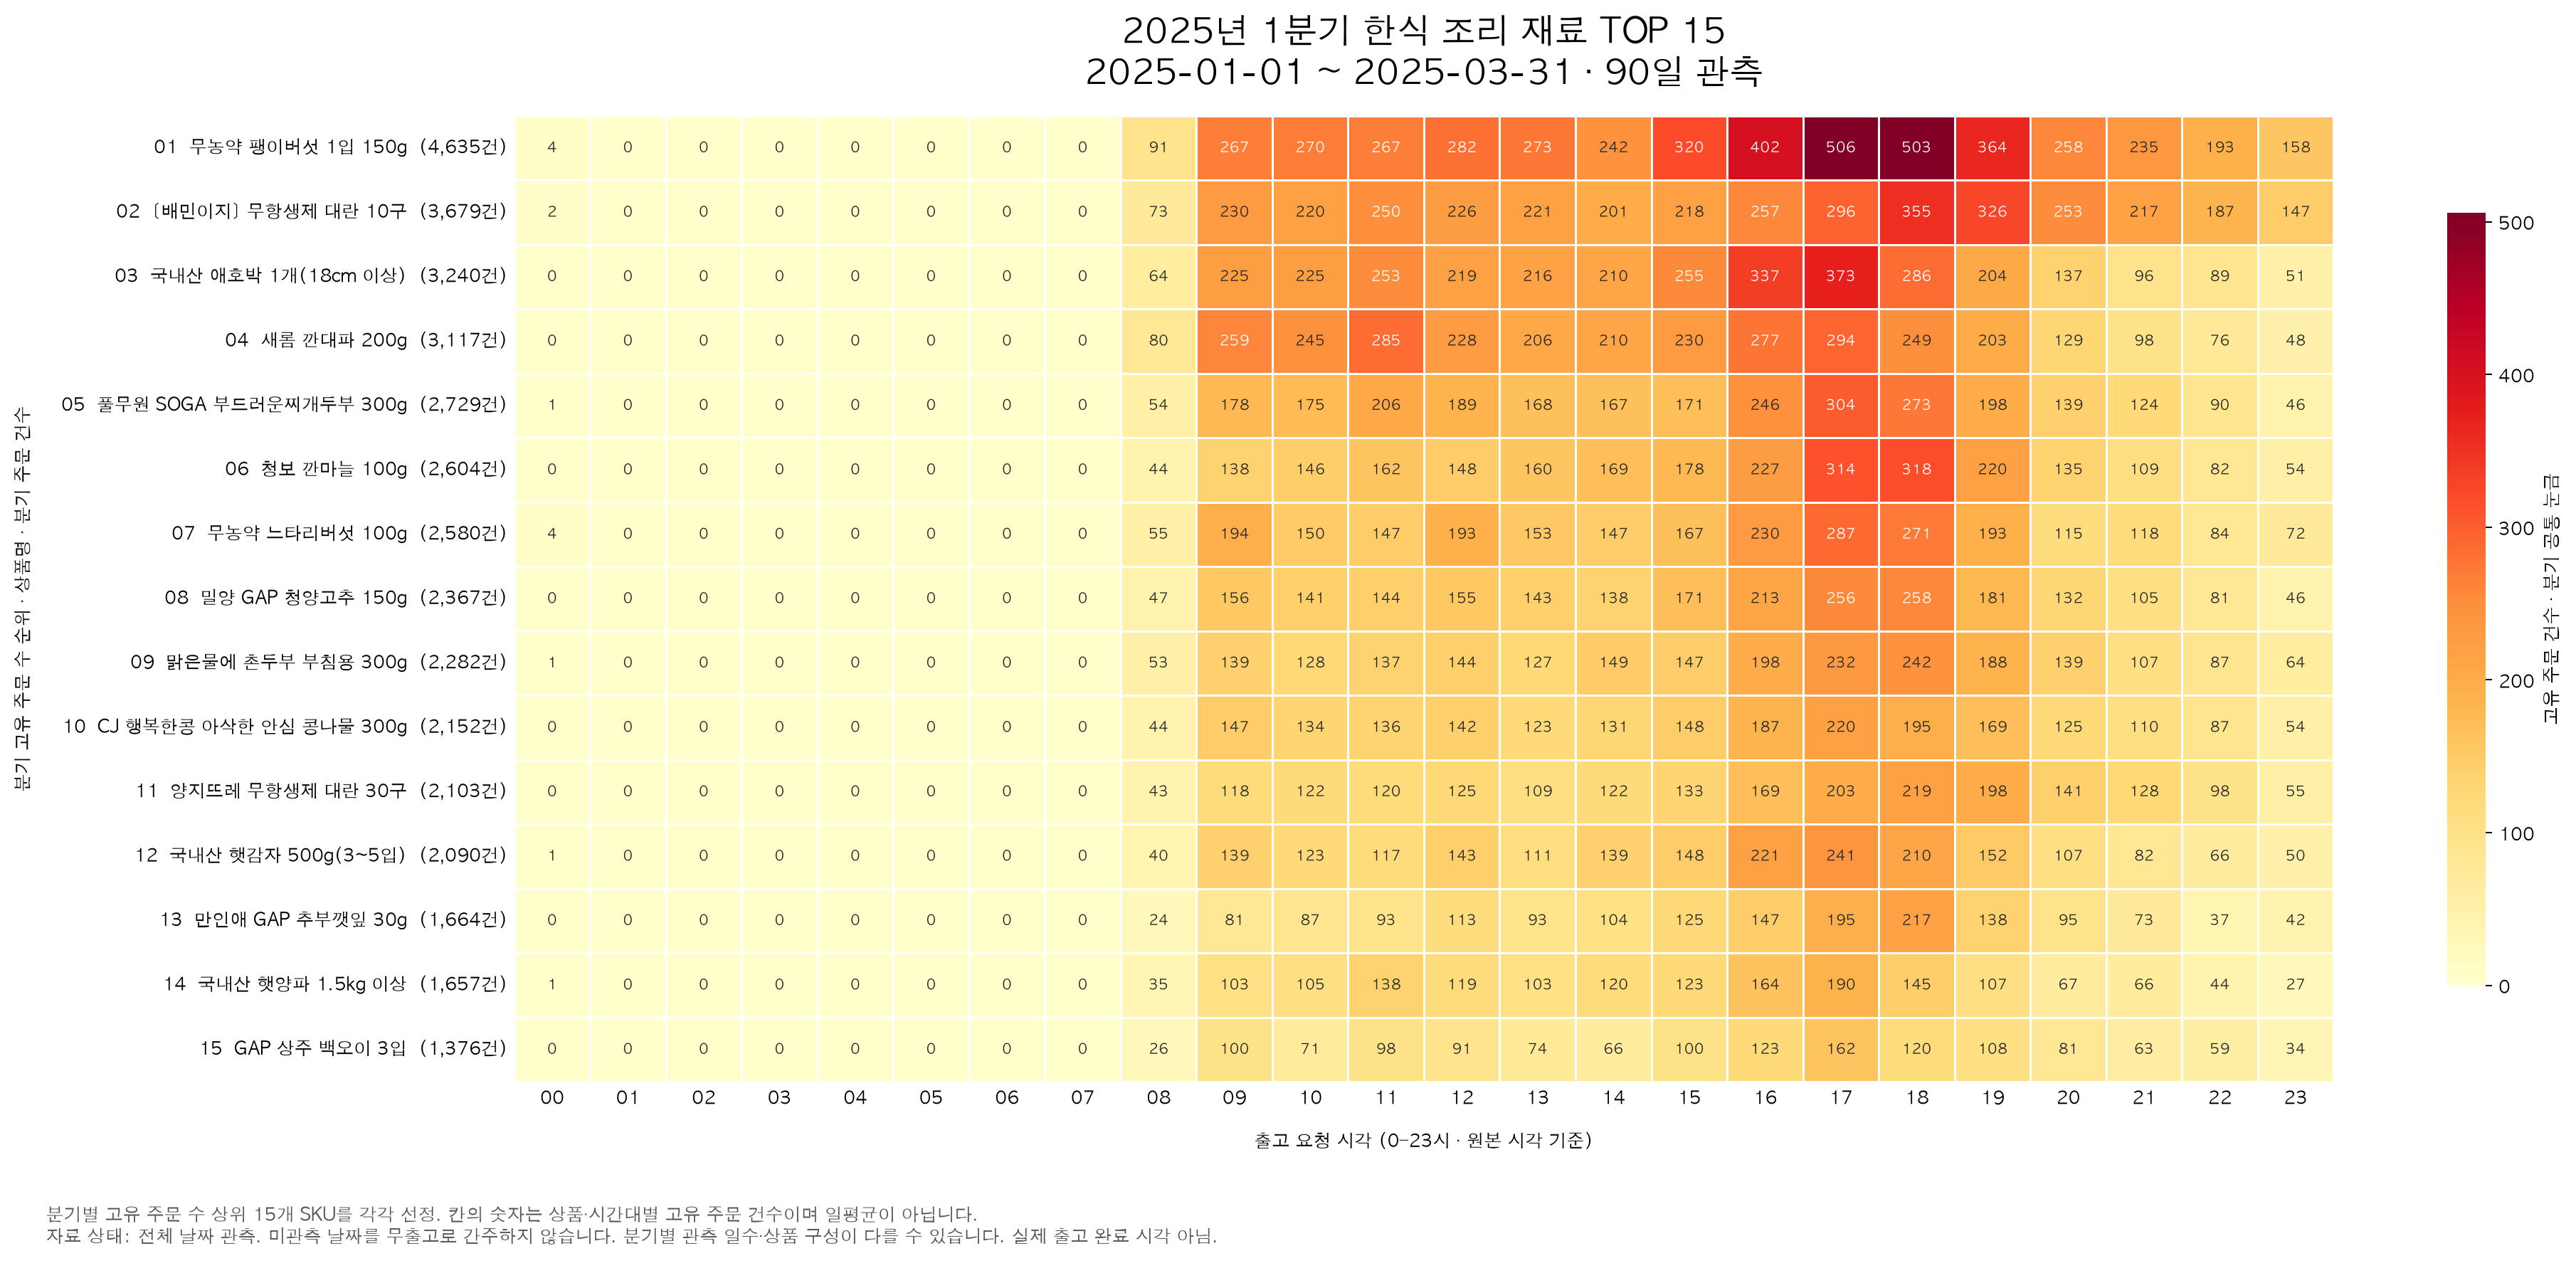

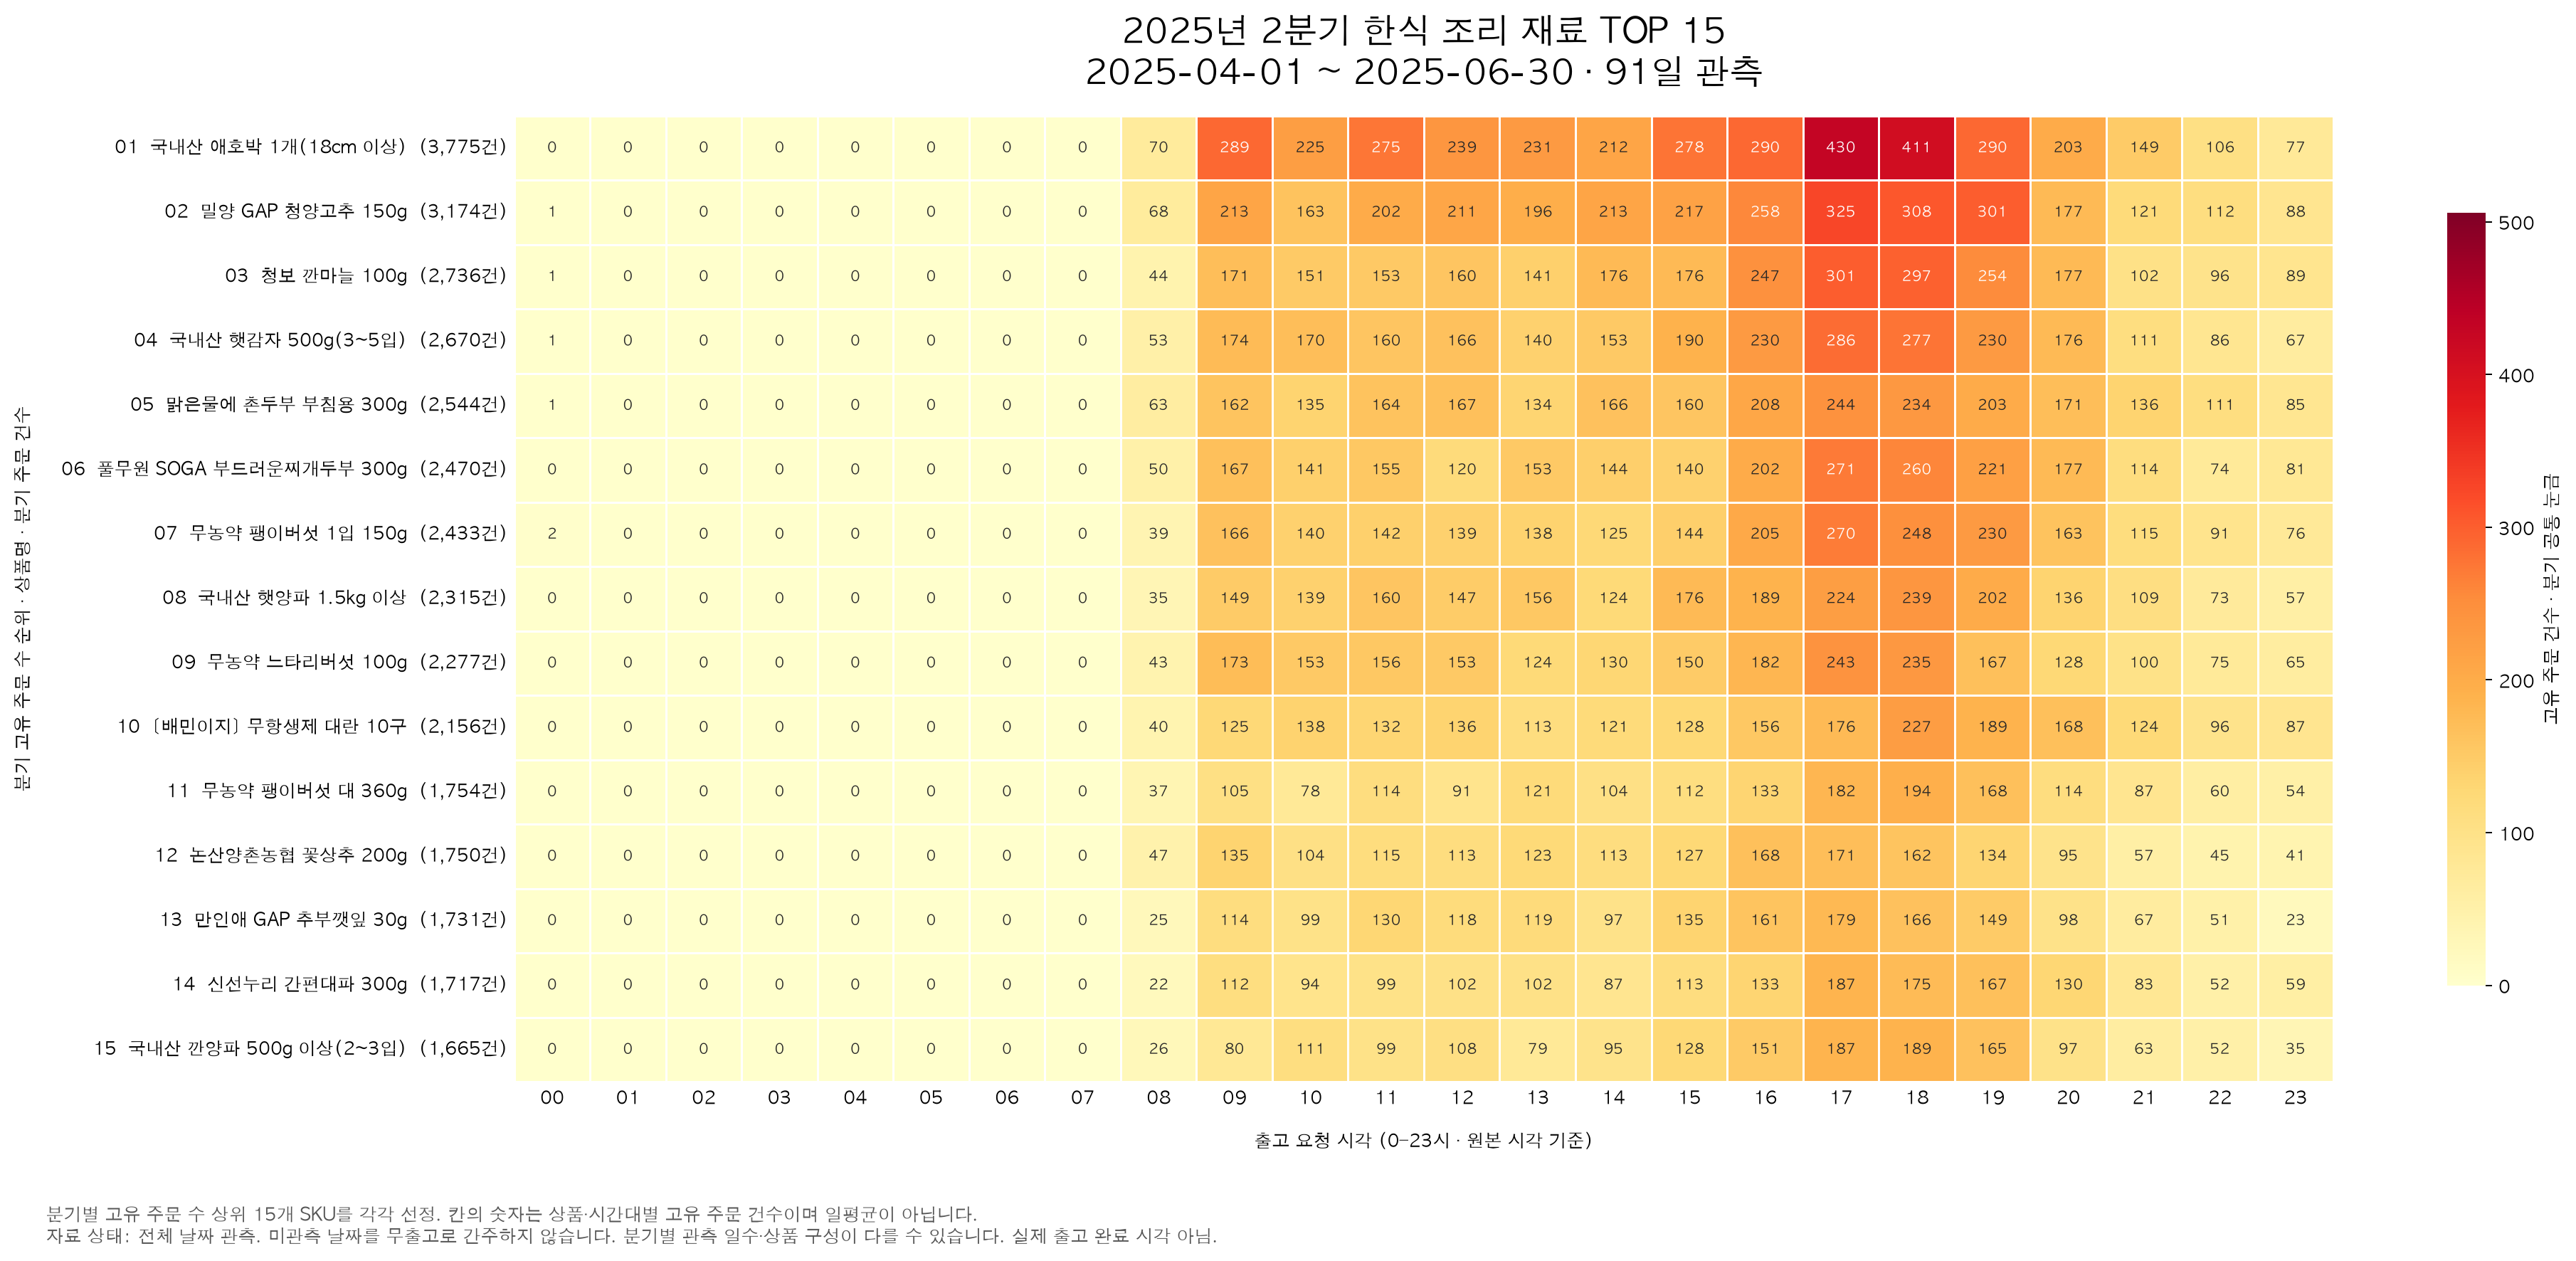

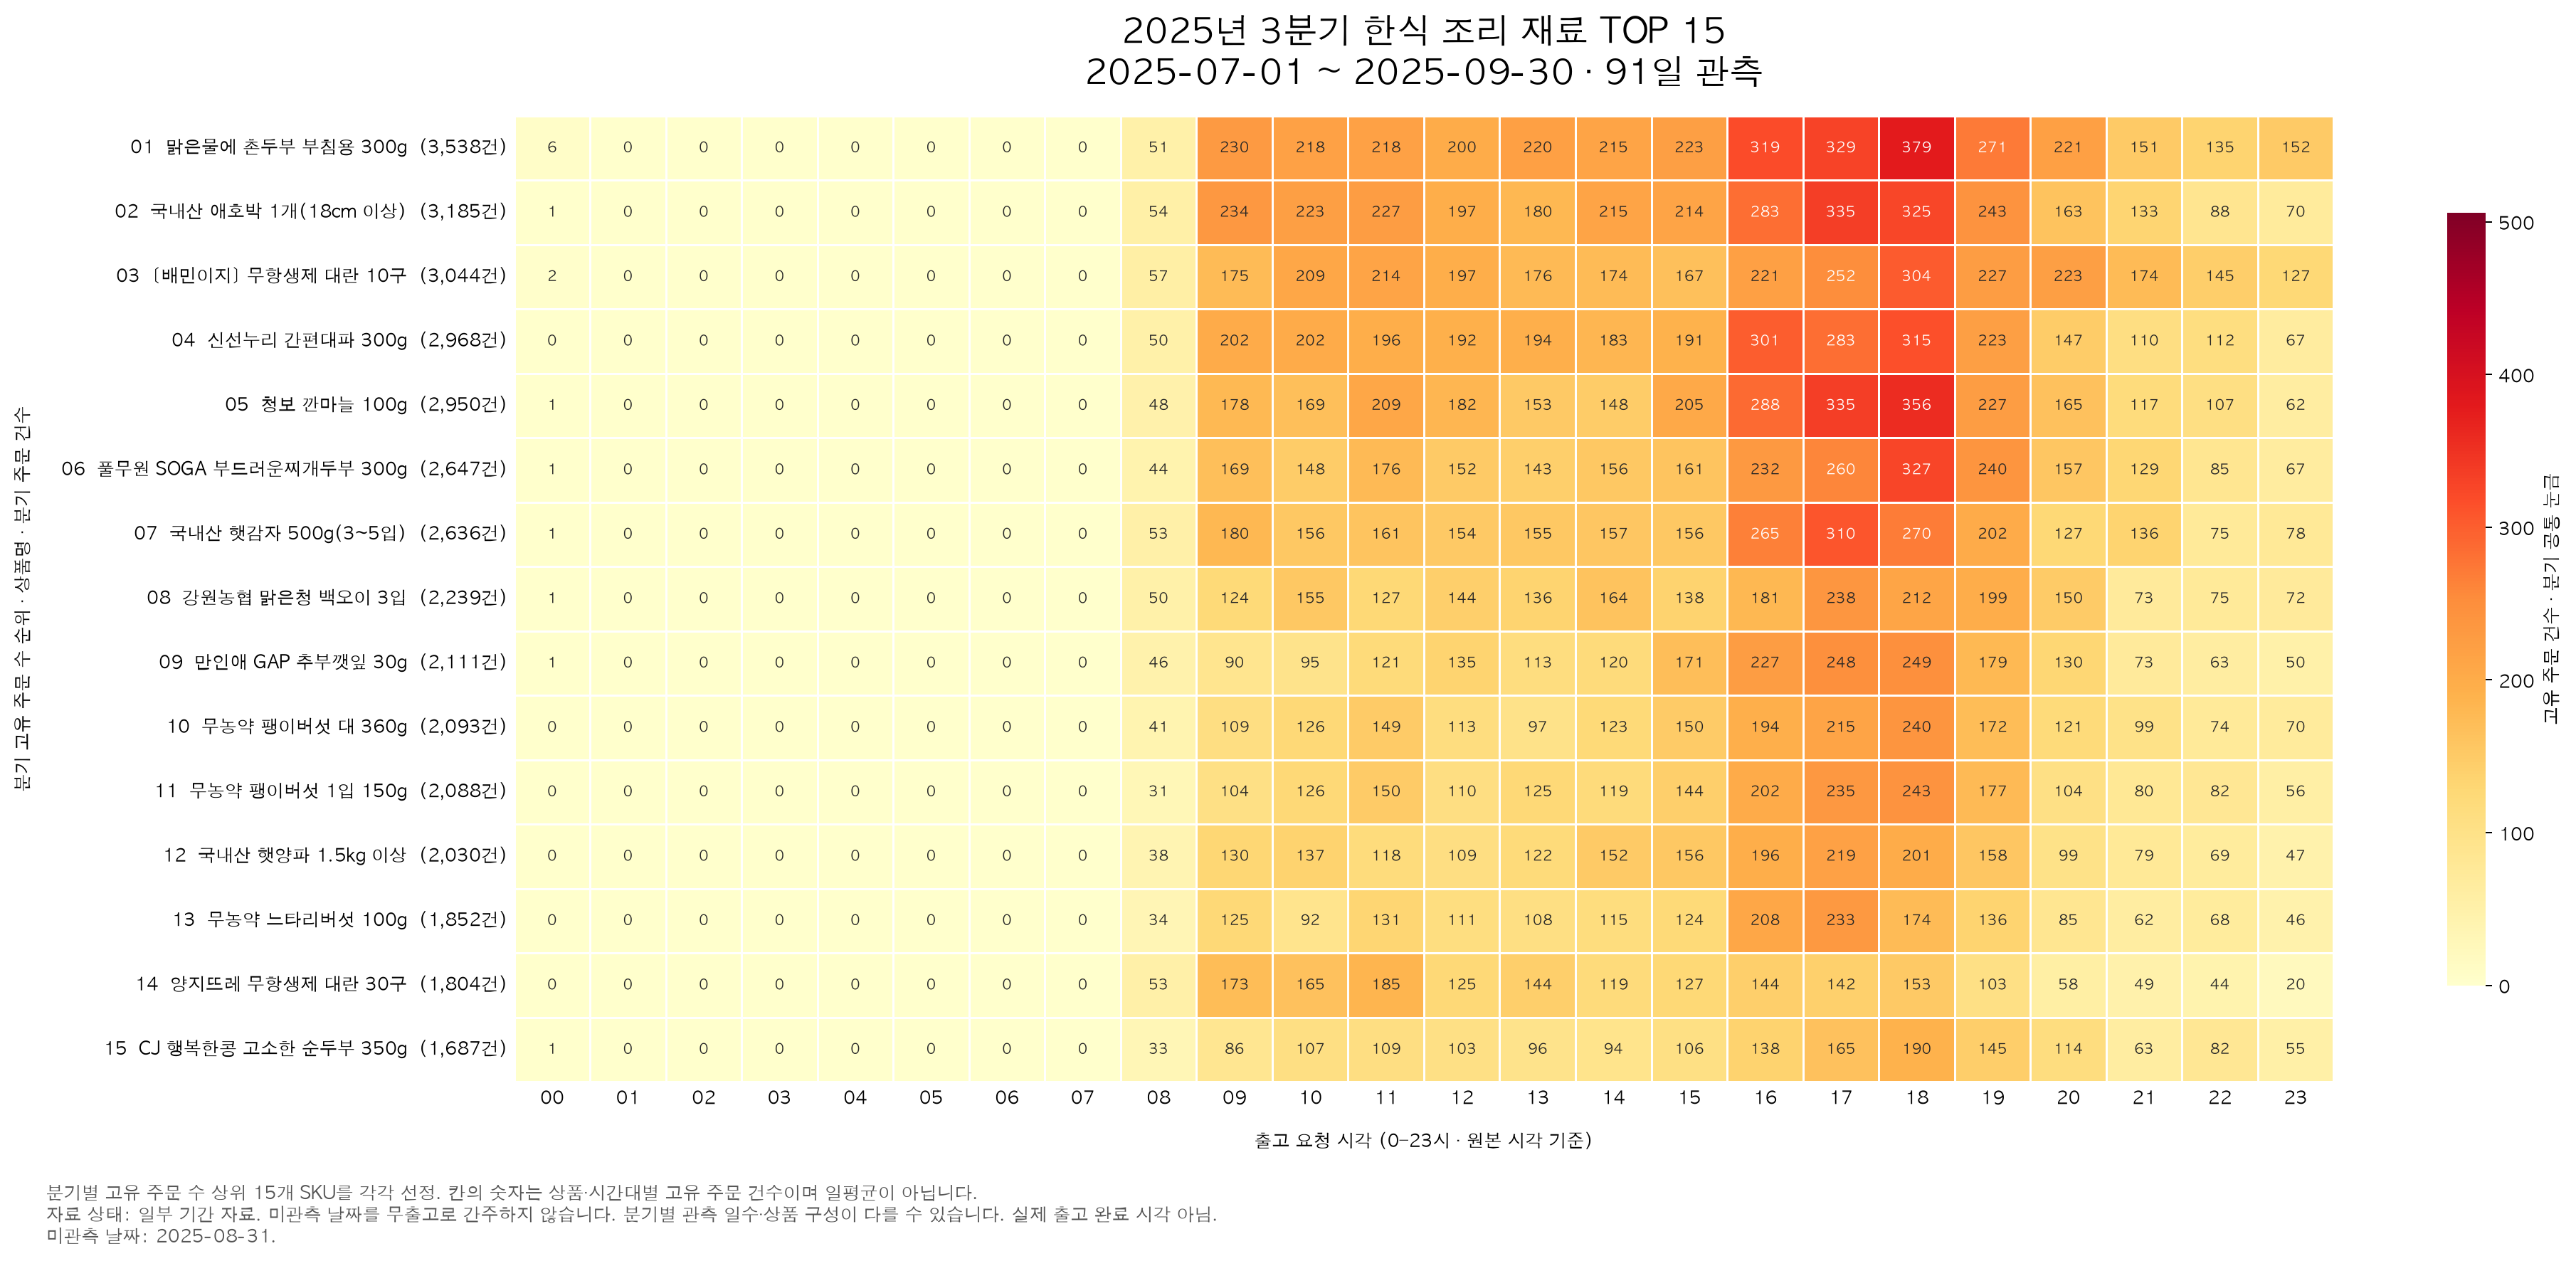

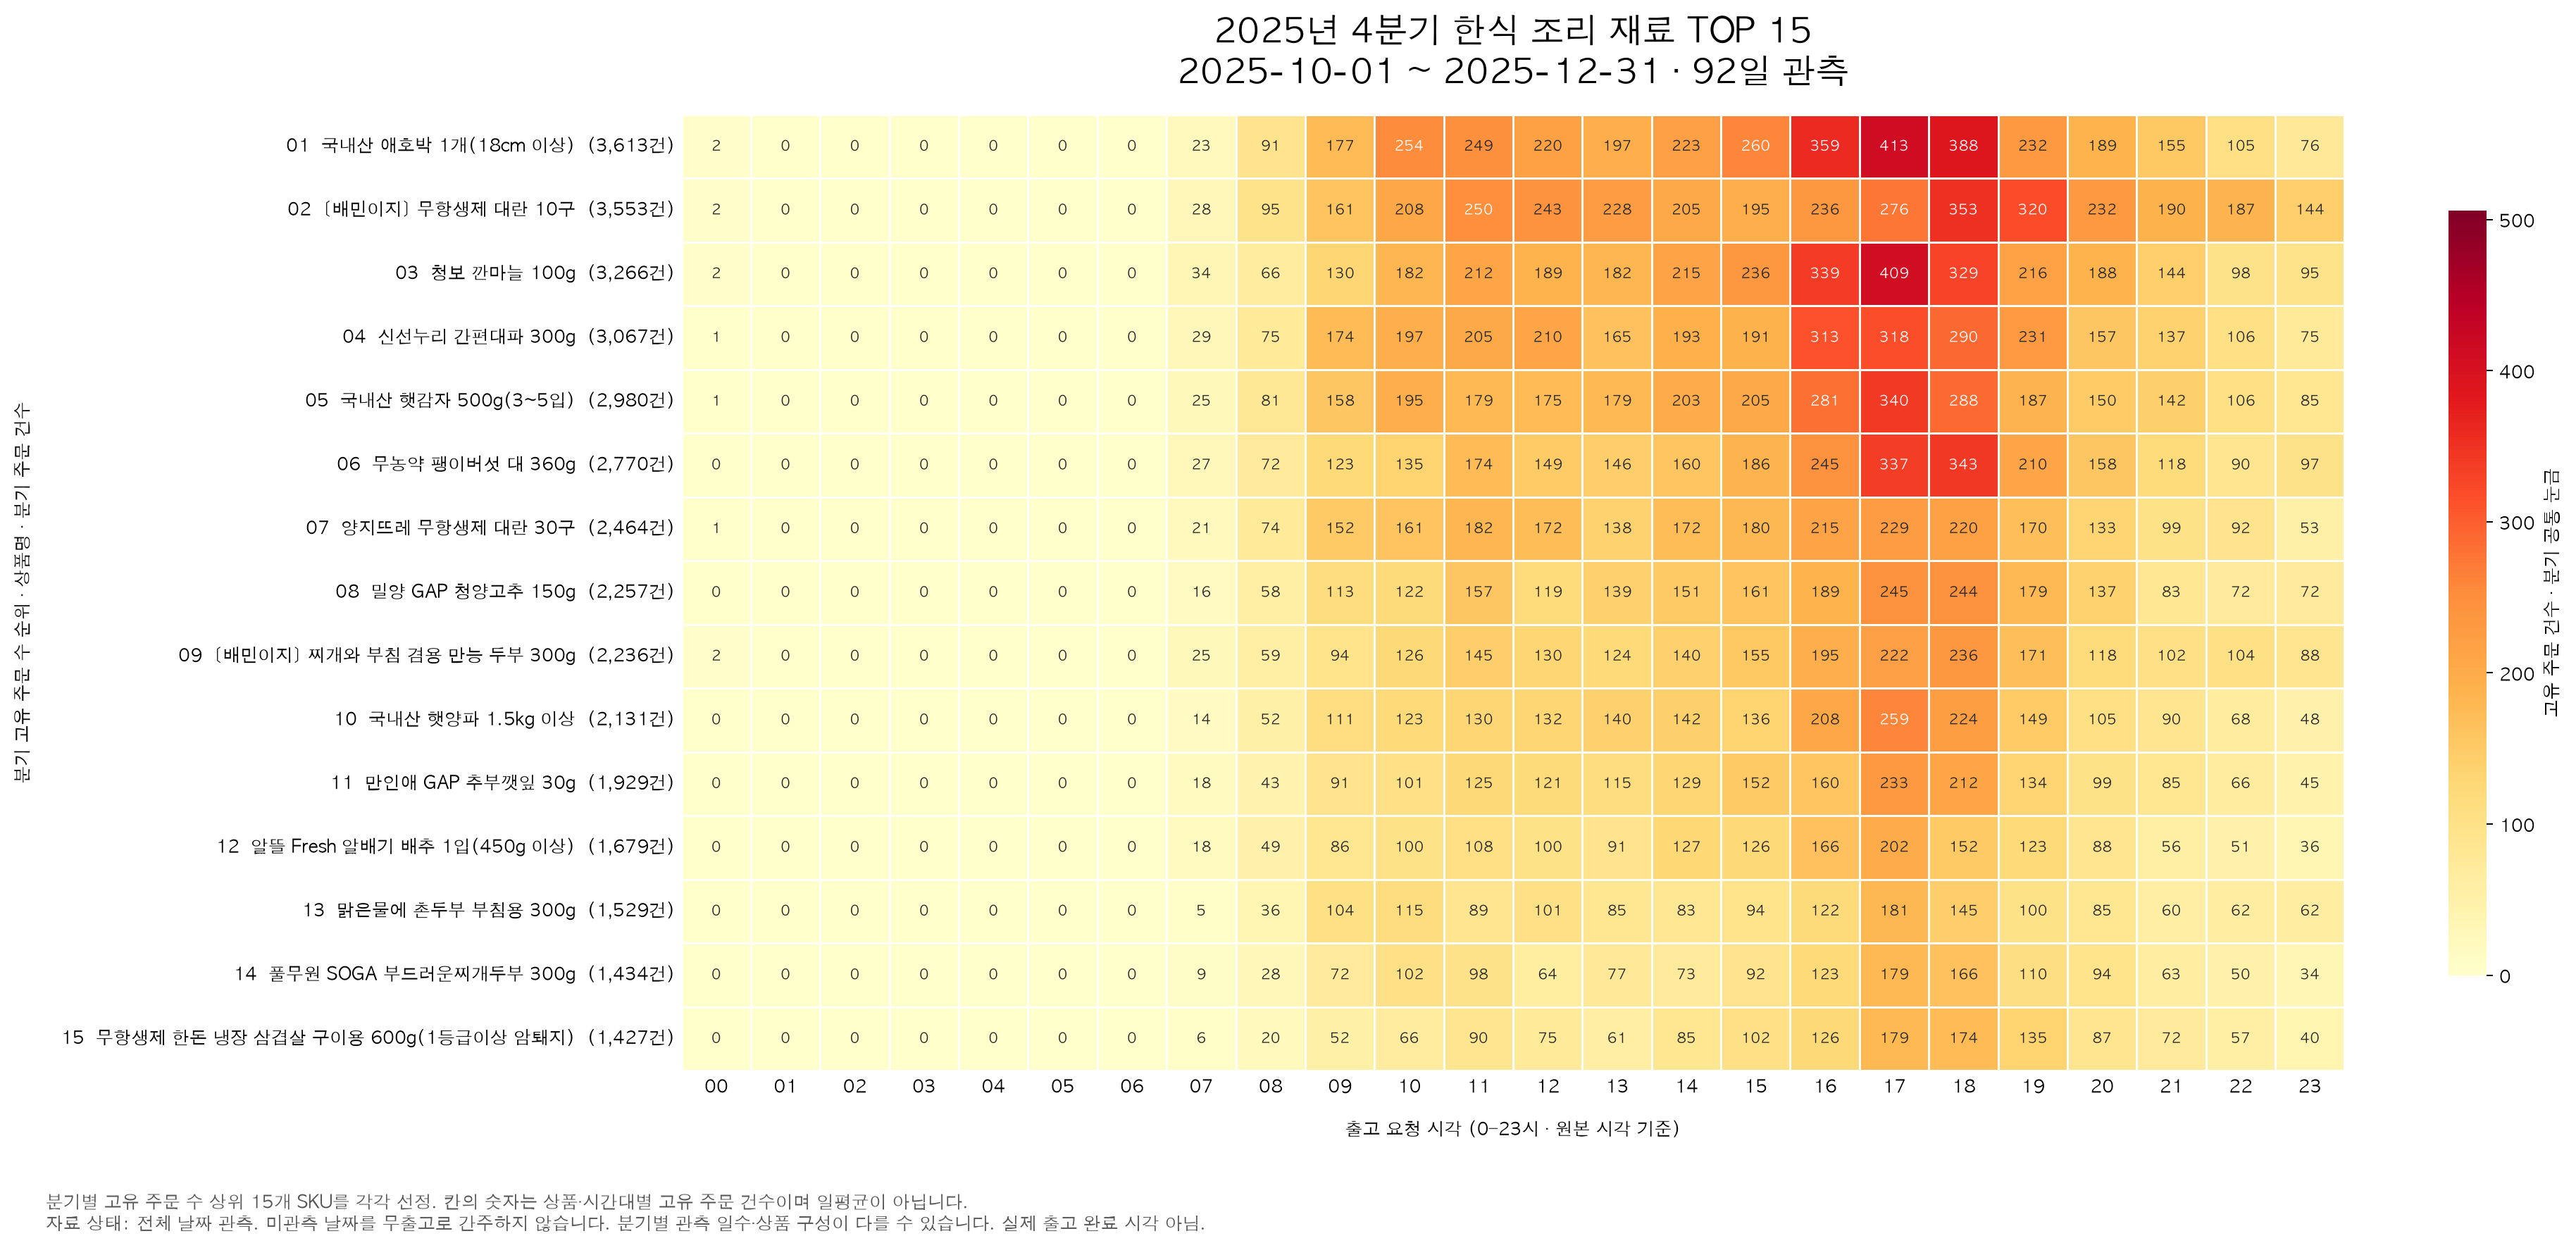

In [5]:
for filename in summary["heatmaps"]:
    display(Image(filename=str(REPORT / filename)))

## 5. 출고 행과 히트맵 일치 확인

각 분기의 TOP 15 선정 및 15 × 24 집계를 출고 행 데이터로 다시 확인합니다.

In [6]:
outbound = pd.read_parquet(DATA / "outbound_ingredients.parquet",
    columns=["requested_at", "sku_code", "hour", "order_id", "picked_quantity"])
outbound["quarter"] = outbound.requested_at.dt.quarter
assert outbound.requested_at.dt.year.eq(YEAR).all()
for quarter, group in top.groupby("quarter"):
    quarter_rows = outbound[outbound.quarter == quarter]
    expected_top = (quarter_rows.groupby("sku_code").agg(
        quarter_order_count=("order_id", "nunique"),
        quarter_picked_quantity=("picked_quantity", "sum")
    ).reset_index().sort_values(
        ["quarter_order_count", "quarter_picked_quantity", "sku_code"],
        ascending=[False, False, True]
    ).head(15))
    assert group.sku_code.tolist() == expected_top.sku_code.tolist()
    table = pd.read_csv(REPORT / f"hansik_{YEAR}_Q{quarter}_top15_hourly_heatmap.csv")
    expected_counts = (quarter_rows.groupby(["sku_code", "hour"]).order_id.nunique()
        .unstack().reindex(index=table.sku_code, columns=range(24)).fillna(0).astype(int))
    assert (expected_counts.to_numpy() == table.iloc[:, 4:].to_numpy()).all()
print("분기별 TOP 15 선정 및 모든 히트맵 칸 검증 통과")
print("Excel:", REPORT / f"hansik_ingredients_{YEAR}_quarterly.xlsx")

분기별 TOP 15 선정 및 모든 히트맵 칸 검증 통과
Excel: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/hansik_2025/hansik_ingredients_2025_quarterly.xlsx
